# Part A: baselines and TF-IDF + logistic regression

Every decision is made on val. The test set is not used in this notebook.

1. Baselines and one-rule shortcuts
2. Category model
3. Polarity model
4. Full pipeline on val

## Setup

In [1]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "AR-aspect-sentiment"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q arabert emoji gensim sentencepiece tashaphyne

OUTPUT_DIR = f"/content/drive/MyDrive/{REPO}"
os.environ["OUTPUT_DIR"] = OUTPUT_DIR
!mkdir -p {OUTPUT_DIR} && cp -rn results {OUTPUT_DIR}/

Mounted at /content/drive
Cloning into '/content/AR-aspect-sentiment'...
remote: Enumerating objects: 67, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 67 (delta 22), reused 64 (delta 19), pack-reused 0 (from 0)
Receiving objects: 100% (67/67), 2.25 MiB | 2.89 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/AR-aspect-sentiment
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [2]:
import pickle
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline, make_union
from sklearn.preprocessing import OneHotEncoder

from src.data import MODELS_DIR, POLARITIES, category_list, category_matrix, load_test, load_train_val, pair_units, pairs
from src.evaluation import (
    THRESHOLD_GRID,
    accuracy_by_mixed_sentence,
    best_category_thresholds,
    best_global_threshold,
    category_report,
    category_scores,
    compare_threshold_policies,
    pairs_from_matrix,
    pipeline_outcomes,
    pipeline_scores,
    polarity_scores,
    predict_labels,
)
from src.plots import (
    plot_category_f1,
    plot_f1_by_threshold,
    plot_model_comparison,
    plot_pipeline_outcomes,
    plot_polarity_confusion,
)
from src.preprocessing import NORM_STEPS, build_pipeline
from src.tracking import latency_ms, log_results, result_row, save_scores

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")

In [3]:
opinions, train, val = load_train_val(SEED)

classes = category_list(opinions)
train_labels = category_matrix(train.categories, classes)
val_labels = category_matrix(val.categories, classes)

train_pairs = pairs(opinions, train)
val_pairs = pairs(opinions, val)
train_units = pair_units(train_pairs)
train_units = train_units[~train_units.ambiguous].reset_index(drop=True)
val_units = pair_units(val_pairs)

print(f"{len(train)} train and {len(val)} val sentences, {len(classes)} categories")
print(f"{len(train_units)} train and {len(val_units)} val (sentence, category) pairs")

4301 train and 481 val sentences, 34 categories
8060 train and 930 val (sentence, category) pairs


In [4]:
result_rows = []

## 1. Baselines and one-rule shortcuts (Q1, Q2)

**Trivial classifier:** every sentence gets `SERVICE#GENERAL`, and every aspect is `positive`.

In [5]:
trivial_predictions = category_matrix([["SERVICE#GENERAL"]] * len(val), classes)
trivial_category = category_scores(val_labels, trivial_predictions)

always_positive = ["positive"] * len(val_units)
trivial_polarity = polarity_scores(val_units, always_positive)

trivial_pairs = val[["sentence_id"]].assign(category="SERVICE#GENERAL", polarity="positive")
trivial_pipeline = pipeline_scores(pipeline_outcomes(val_pairs, trivial_pairs))

result_rows.append(result_row("category", "trivial", **trivial_category))
result_rows.append(result_row("polarity", "trivial", **trivial_polarity))
result_rows.append(result_row("pipeline", "trivial", micro_f1=trivial_pipeline["pipeline_f1"]))

print("Categories:", trivial_category)
print("Polarity:", trivial_polarity)
print("Pipeline:", trivial_pipeline)

Categories: {'micro_f1': 0.23529411764705882, 'macro_f1': 0.015092281116465133, 'precision': 0.34511434511434513, 'recall': 0.17849462365591398}
Polarity: {'accuracy': 0.5711183496199783, 'macro_f1': 0.2423404745450357}
Pipeline: {'category_f1': 0.23529411764705882, 'pipeline_f1': 0.16017009213323885}


**Keyword rule:** one word gives one category. The keywords are matched on normalized text.

In [6]:
KEYWORD_RULES = {
    "فندق": "HOTEL#GENERAL",
    "غرف": "ROOMS#GENERAL",
    "موقع": "LOCATION#GENERAL",
    "موظف": "SERVICE#GENERAL",
    "خدم": "SERVICE#GENERAL",
    "استقبال": "SERVICE#GENERAL",
    "افطار": "FOOD_DRINKS#QUALITY",
    "فطور": "FOOD_DRINKS#QUALITY",
    "طعام": "FOOD_DRINKS#QUALITY",
    "سعر": "HOTEL#PRICES",
    "نظاف": "ROOMS#CLEANLINESS",
    "نظيف": "ROOMS#CLEANLINESS",
    "مسبح": "FACILITIES#GENERAL",
    "حمام": "ROOMS_AMENITIES#GENERAL",
}

normalize = build_pipeline(NORM_STEPS)
normalized_val_text = val.text.map(normalize)

keyword_categories = [
    sorted({category for keyword, category in KEYWORD_RULES.items() if keyword in text})
    for text in normalized_val_text
]
keyword_predictions = category_matrix(keyword_categories, classes)
keyword_scores = category_scores(val_labels, keyword_predictions)

result_rows.append(result_row("category", "keyword rule", **keyword_scores))
keyword_scores

{'micro_f1': 0.4648648648648649,
 'macro_f1': 0.12770397002045888,
 'precision': 0.5265306122448979,
 'recall': 0.4161290322580645}

In [7]:
keyword_table = []
for keyword, category in KEYWORD_RULES.items():
    has_keyword = normalized_val_text.str.contains(keyword).to_numpy()
    has_category = val_labels[:, classes.index(category)] == 1
    keyword_table.append({
        "keyword": keyword,
        "category": category,
        "sentences": has_keyword.sum(),
        "precision": (has_keyword & has_category).sum() / max(has_keyword.sum(), 1),
        "share_of_category_found": (has_keyword & has_category).sum() / max(has_category.sum(), 1),
    })

pd.DataFrame(keyword_table).round(2)

,keyword,category,sentences,precision,share_of_category_found
0,فندق,HOTEL#GENERAL,217,0.49,0.75
1,غرف,ROOMS#GENERAL,135,0.23,0.94
2,موقع,LOCATION#GENERAL,46,0.80,0.42
3,موظف,SERVICE#GENERAL,37,0.95,0.21
4,خدم,SERVICE#GENERAL,82,0.83,0.41
5,استقبال,SERVICE#GENERAL,46,0.89,0.25
6,افطار,FOOD_DRINKS#QUALITY,36,0.58,0.33
7,فطور,FOOD_DRINKS#QUALITY,8,0.38,0.05
8,طعام,FOOD_DRINKS#QUALITY,32,0.66,0.33
9,سعر,HOTEL#PRICES,19,0.84,0.48


**Sentence polarity rule:** every aspect of a sentence gets the same polarity, the majority polarity of its gold aspects.

This rule cheats, because it reads the gold labels. It is the best score any "one polarity per sentence" method can reach.

In [8]:
sentence_polarity = val_pairs.groupby("sentence_id").polarity.agg(lambda polarities: polarities.mode()[0])
copied_polarities = val_units.sentence_id.map(sentence_polarity)
sentence_rule_scores = polarity_scores(val_units, copied_polarities)

result_rows.append(result_row("polarity", "sentence polarity rule (gold)", **sentence_rule_scores))
sentence_rule_scores

{'accuracy': 0.9163952225841476, 'macro_f1': 0.8457296527925807}

**Conclusions (Q1, Q2)**

* The trivial classifier gets micro-F1 0.235 and macro-F1 0.015, and always-positive gets 57% accuracy but macro-F1 0.24. Accuracy alone would look fine here, so polarity is judged on macro-F1.
* The keyword rule alone reaches micro-F1 0.465, about 77% of the TF-IDF model's score. Category detection is largely a matter of spotting surface words, so a good score does not prove real understanding.
* `موظف` and `استقبال` predict `SERVICE#GENERAL` very well (precision 0.95 and 0.89). `غرف` is weak for `ROOMS#GENERAL` (0.23), because room sentences are spread over several `ROOMS#` categories.
* Copying the majority gold polarity gives accuracy 0.916 and macro-F1 0.846. This upper bound is above the real polarity model, so sentence-level sentiment explains most of this task.

## 2. Category model

Words 1-2 and characters 2-5 TF-IDF, then one logistic regression per category.

In [9]:
PREPROCESSINGS = {
    "raw": [],
    "punct": ["punctuation"],
    "letters+punct": ["letters", "punctuation"],
    "norm": NORM_STEPS,
    "norm+long_numbers": NORM_STEPS + ["long_numbers"],
    "norm+digits": NORM_STEPS + ["digits"],
    "norm+light_stem": NORM_STEPS + ["light_stem"],
    "norm+stem": NORM_STEPS + ["stem"],
}
C_VALUES = [0.1, 0.5, 1.0, 5.0, 10.0, 100.0, 300.0, 1000.0]

In [10]:
def make_tfidf():
    return make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
    )


def make_category_classifier(C):
    return OneVsRestClassifier(LogisticRegression(C=C, max_iter=1000), n_jobs=-1)

### Grid search

The TF-IDF does not depend on `C`, so it is fitted once per preprocessing, on train only.

The two threshold strategies are both tuned on val. The per-category score is therefore optimistic: section "Global or per-category threshold" measures by how much.

In [11]:
grid_rows = []

for preprocessing_name, steps in PREPROCESSINGS.items():
    prepare_text = build_pipeline(steps)
    tfidf = make_tfidf()
    train_features = tfidf.fit_transform(train.text.map(prepare_text))
    val_features = tfidf.transform(val.text.map(prepare_text))

    for C in C_VALUES:
        start = time.time()
        classifier = make_category_classifier(C).fit(train_features, train_labels)
        fit_time = time.time() - start
        val_scores = classifier.predict_proba(val_features)

        global_threshold, _ = best_global_threshold(val_scores, val_labels)
        category_thresholds = best_category_thresholds(val_scores, val_labels, global_threshold)
        with_global = category_scores(val_labels, predict_labels(val_scores, global_threshold))
        with_per_category = category_scores(val_labels, predict_labels(val_scores, category_thresholds))

        grid_rows.append({
            "preprocessing": preprocessing_name,
            "C": C,
            "global_threshold": global_threshold,
            "micro_f1_global": with_global["micro_f1"],
            "macro_f1_global": with_global["macro_f1"],
            "micro_f1_per_category": with_per_category["micro_f1"],
            "macro_f1_per_category": with_per_category["macro_f1"],
            "fit_time_s": fit_time,
        })

    best_so_far = max(row["micro_f1_global"] for row in grid_rows if row["preprocessing"] == preprocessing_name)
    print(f"{preprocessing_name}: best micro-F1 {best_so_far:.4f}")

category_grid = pd.DataFrame(grid_rows).sort_values("micro_f1_global", ascending=False).reset_index(drop=True)
category_grid.head(8).round(4)

raw: best micro-F1 0.6005
punct: best micro-F1 0.5963
letters+punct: best micro-F1 0.6016
norm: best micro-F1 0.5975
norm+long_numbers: best micro-F1 0.5971
norm+digits: best micro-F1 0.5964
norm+light_stem: best micro-F1 0.6035
norm+stem: best micro-F1 0.5962


,preprocessing,C,global_threshold,micro_f1_global,macro_f1_global,micro_f1_per_category,macro_f1_per_category,fit_time_s
0,norm+light_stem,5.0,0.22,0.6035,0.2600,0.6116,0.3773,12.7168
1,letters+punct,100.0,0.18,0.6016,0.3035,0.6125,0.3755,20.1482
2,norm+light_stem,10.0,0.22,0.6016,0.2740,0.6057,0.3762,12.6491
3,letters+punct,300.0,0.12,0.6006,0.3136,0.6138,0.3677,20.4163
4,raw,100.0,0.14,0.6005,0.2900,0.6093,0.3739,27.0885
5,raw,10.0,0.18,0.5990,0.2783,0.5875,0.3709,26.3227
6,norm+light_stem,100.0,0.18,0.5986,0.3008,0.6134,0.3811,14.1273
7,norm+light_stem,300.0,0.14,0.5981,0.3163,0.6159,0.3825,13.3677


The best model is chosen with the global threshold: it has one tuned value, so it is the less optimistic score.

**Left:** every combination. **Right:** what each preprocessing gains over `raw` (Q3), each at its best `C`.

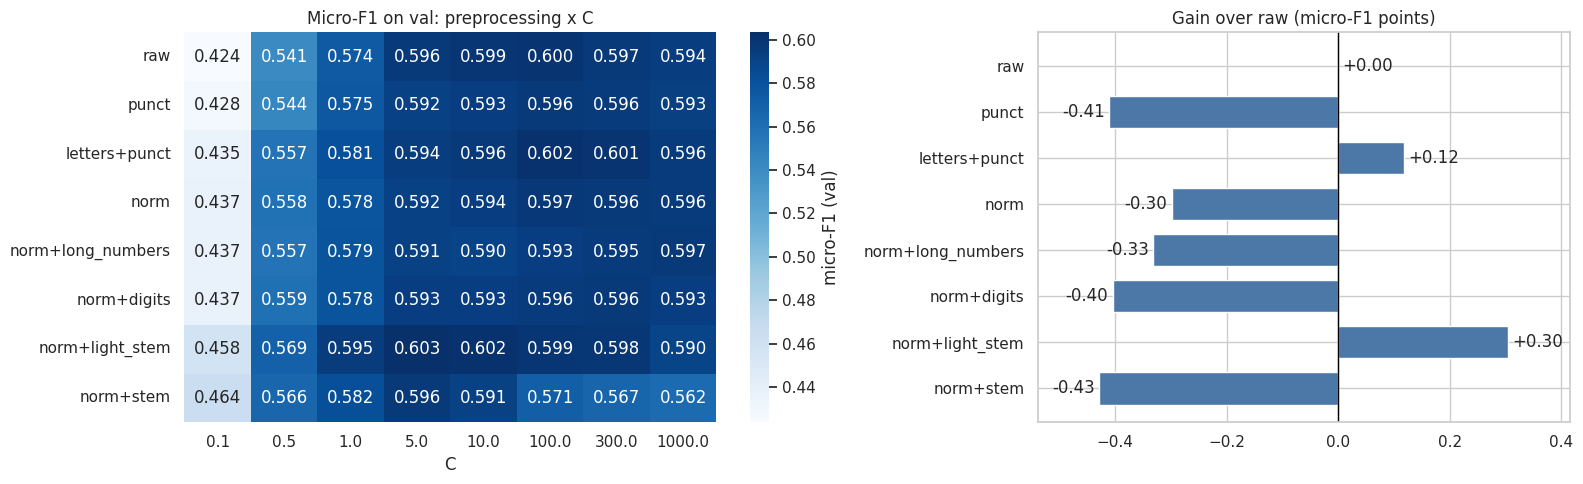

In [12]:
preprocessing_order = list(PREPROCESSINGS)
heatmap_table = category_grid.pivot(index="preprocessing", columns="C", values="micro_f1_global").loc[preprocessing_order]

best_by_preprocessing = category_grid.loc[category_grid.groupby("preprocessing").micro_f1_global.idxmax()]
best_by_preprocessing = best_by_preprocessing.set_index("preprocessing").loc[preprocessing_order]
gain_over_raw = (best_by_preprocessing.micro_f1_global - best_by_preprocessing.micro_f1_global["raw"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.25, 1]})

sns.heatmap(heatmap_table, annot=True, fmt=".3f", cmap="Blues", ax=axes[0], cbar_kws={"label": "micro-F1 (val)"})
axes[0].set_title("Micro-F1 on val: preprocessing x C")
axes[0].set_ylabel("")

gain_bars = axes[1].barh(preprocessing_order, gain_over_raw, color="#4C78A8", height=0.7)
axes[1].bar_label(gain_bars, fmt="%+.2f", padding=3)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].invert_yaxis()
axes[1].margins(x=0.15)
axes[1].set_title("Gain over raw (micro-F1 points)")

plt.tight_layout()
plt.show()

### Refit the best model

In [13]:
best_run = category_grid.iloc[0]
category_steps = PREPROCESSINGS[best_run.preprocessing]
prepare_category_text = build_pipeline(category_steps)
best_C = float(best_run.C)

category_model = Pipeline([("tfidf", make_tfidf()), ("classifier", make_category_classifier(best_C))])
category_model.fit(train.text.map(prepare_category_text), train_labels)
val_scores = category_model.predict_proba(val.text.map(prepare_category_text))

print(f"Best: {best_run.preprocessing}, C={best_C:g}")

Best: norm+light_stem, C=5


### Global or per-category threshold (Q6)

Tuning a threshold and scoring it on the same sentences flatters the per-category version, which has 34 tuned values. To get an honest comparison, thresholds are tuned on half of the val reviews and scored on the other half, 200 times. Tuning on half of val is hard on the per-category version, so this comparison is a guide, not an exact measure.

In [14]:
holdout = compare_threshold_policies(val_scores, val_labels, val.review_id, seed=SEED)
per_category_win_rate = (holdout.micro_f1_per_category > holdout.micro_f1_global).mean()
print(f"Per-category beats global on micro-F1 in {per_category_win_rate:.0%} of the splits")
holdout.mean().round(4)

Per-category beats global on micro-F1 in 1% of the splits


,0
micro_f1_global,0.5994
micro_f1_per_category,0.5617
macro_f1_global,0.2652
macro_f1_per_category,0.3110


In [15]:
global_threshold, f1_curve = best_global_threshold(val_scores, val_labels)
per_category_thresholds = best_category_thresholds(val_scores, val_labels, global_threshold)

use_per_category = holdout.micro_f1_per_category.mean() > holdout.micro_f1_global.mean()
threshold_policy = "per_category" if use_per_category else "global"
chosen_thresholds = per_category_thresholds if use_per_category else global_threshold

val_predictions = predict_labels(val_scores, chosen_thresholds)
category_result = category_scores(val_labels, val_predictions)

print("Chosen policy:", threshold_policy)
category_result

Chosen policy: global


{'micro_f1': 0.6034968979131415,
 'macro_f1': 0.2599828088742143,
 'precision': 0.6346381969157769,
 'recall': 0.5752688172043011}

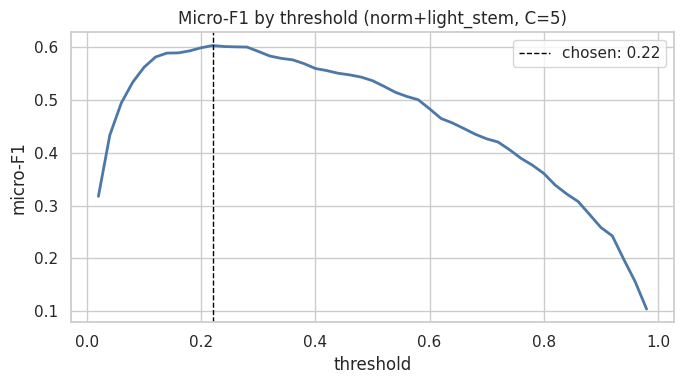

In [16]:
plot_f1_by_threshold(THRESHOLD_GRID, f1_curve, global_threshold, title=f"Micro-F1 by threshold ({best_run.preprocessing}, C={best_C:g})")

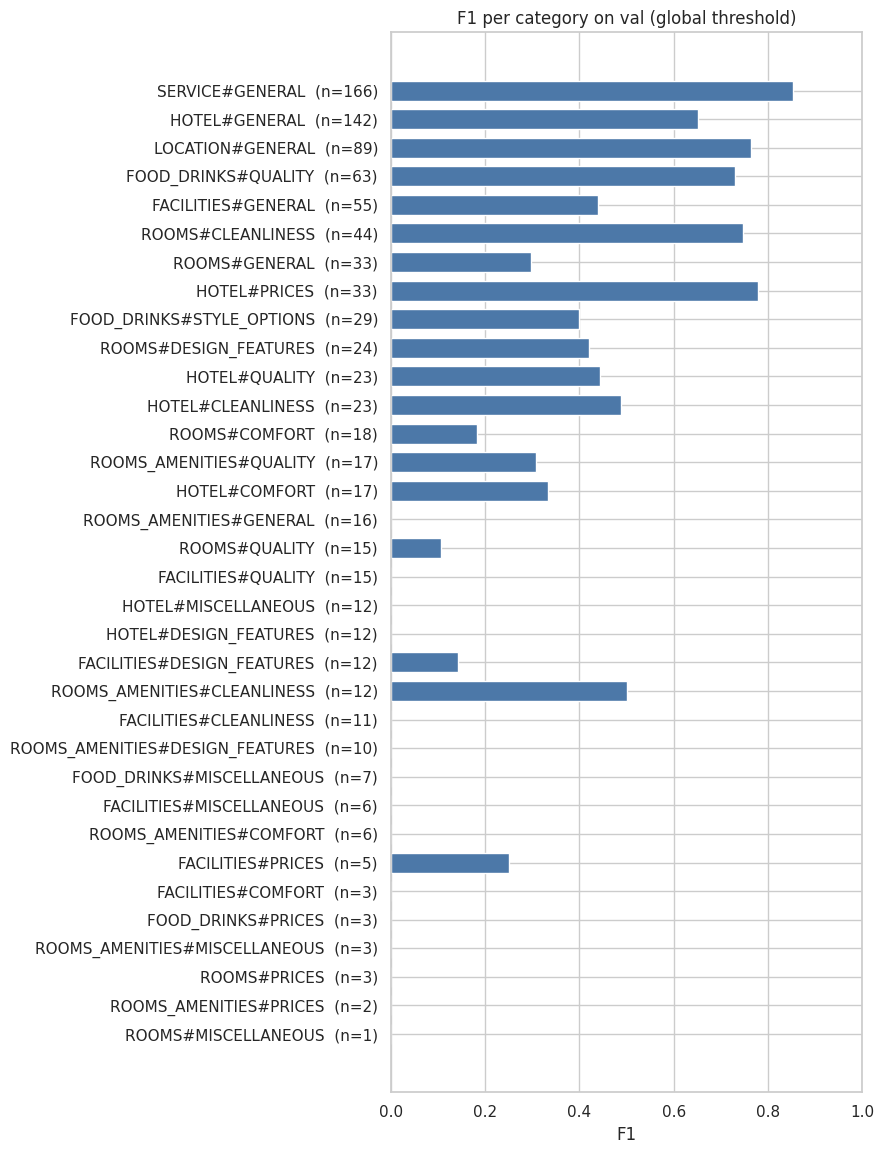

In [17]:
report = category_report(val_labels, val_predictions, classes)
plot_category_f1(report, title=f"F1 per category on val ({threshold_policy} threshold)")

In [18]:
never_predicted = report[report.predicted == 0]
print(f"{len(never_predicted)} categories are never predicted")
never_predicted[["category", "support"]]

9 categories are never predicted


,category,support
18,HOTEL#MISCELLANEOUS,12
22,FACILITIES#CLEANLINESS,11
23,ROOMS_AMENITIES#DESIGN_FEATURES,10
24,FOOD_DRINKS#MISCELLANEOUS,7
26,ROOMS_AMENITIES#COMFORT,6
28,FACILITIES#COMFORT,3
30,ROOMS_AMENITIES#MISCELLANEOUS,3
32,ROOMS_AMENITIES#PRICES,2
33,ROOMS#MISCELLANEOUS,1


In [19]:
for row in category_grid.itertuples():
    params = f"C={row.C:g}"
    common = {"preprocessing": row.preprocessing, "params": params, "fit_time_s": row.fit_time_s}
    result_rows.append(result_row("category", "tfidf+lr", threshold_policy="global", micro_f1=row.micro_f1_global,
                                  macro_f1=row.macro_f1_global, **common))
    result_rows.append(result_row("category", "tfidf+lr", threshold_policy="per_category", micro_f1=row.micro_f1_per_category,
                                  macro_f1=row.macro_f1_per_category, **common))

**Conclusions (Q3, Q6)**

* All preprocessings land between 0.596 and 0.604 at their best `C`. With 481 val sentences these gaps are too small to treat as real: normalization barely matters for TF-IDF, because character n-grams already absorb spelling variation. Full stemming does not help.
* The best model is `norm+light_stem`, `C=5`, micro-F1 0.603 and macro-F1 0.260 with a global threshold of 0.22.
* Scored on the same val data, per-category thresholds look better (0.612), but that is overfitting. On held-out val reviews they lose on micro-F1 (0.562 vs 0.599) and beat the global threshold in only 1% of splits, while macro-F1 improves (0.311 vs 0.265). The official metric is micro-F1, so the global threshold is kept.
* 9 categories are never predicted, all with 12 val examples or fewer. A single global threshold gives up on the long tail.

## 3. Polarity model

The same text features plus a one-hot of the category, then one 3-class logistic regression. `class_weight="balanced"` is how `neutral` gets a fair weight.

In a linear model the one-hot only shifts the score of each polarity: it does not change which words count for that aspect. Two aspects of the same sentence therefore get nearly the same answer.

In [20]:
POLARITY_PREPROCESSINGS = ["raw", "norm", "norm+digits", "norm+light_stem"]
POLARITY_C_VALUES = [0.1, 1.0, 10.0, 100.0]
CLASS_WEIGHTS = {"none": None, "balanced": "balanced"}


def make_polarity_model(C, class_weight):
    features = ColumnTransformer([
        ("words", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "text"),
        ("characters", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True), "text"),
        ("category", OneHotEncoder(handle_unknown="ignore"), ["category"]),
    ])
    classifier = LogisticRegression(C=C, class_weight=class_weight, max_iter=1000)
    return Pipeline([("features", features), ("classifier", classifier)])


def with_prepared_text(table, prepare_text):
    return table.assign(text=table.text.map(prepare_text))

In [21]:
polarity_rows = []

for preprocessing_name in POLARITY_PREPROCESSINGS:
    prepare_text = build_pipeline(PREPROCESSINGS[preprocessing_name])
    train_inputs = with_prepared_text(train_units, prepare_text)
    val_inputs = with_prepared_text(val_units, prepare_text)

    for C in POLARITY_C_VALUES:
        for weight_name, class_weight in CLASS_WEIGHTS.items():
            start = time.time()
            model = make_polarity_model(C, class_weight).fit(train_inputs, train_inputs.polarity)
            fit_time = time.time() - start
            scores = polarity_scores(val_units, model.predict(val_inputs))
            polarity_rows.append({"preprocessing": preprocessing_name, "C": C, "class_weight": weight_name,
                                  "fit_time_s": fit_time, **scores})

polarity_grid = pd.DataFrame(polarity_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
polarity_grid.head(8).round(4)

,preprocessing,C,class_weight,fit_time_s,accuracy,macro_f1
0,norm+light_stem,100.0,balanced,23.2636,0.8317,0.6881
1,raw,1.0,balanced,20.8881,0.8187,0.6828
2,norm+light_stem,10.0,balanced,17.4791,0.8241,0.6770
3,norm+digits,1.0,balanced,17.1937,0.8154,0.6727
4,norm,10.0,balanced,21.2791,0.8219,0.6707
5,norm,1.0,balanced,19.0694,0.8122,0.6687
6,norm+digits,10.0,balanced,25.1271,0.8241,0.6677
7,raw,10.0,balanced,28.9028,0.8252,0.6673


Best: norm+light_stem, C=100, class_weight=balanced
              precision    recall  f1-score   support

    negative       0.81      0.87      0.84       341
     neutral       0.40      0.31      0.35        54
    positive       0.88      0.86      0.87       526

    accuracy                           0.83       921
   macro avg       0.70      0.68      0.69       921
weighted avg       0.83      0.83      0.83       921



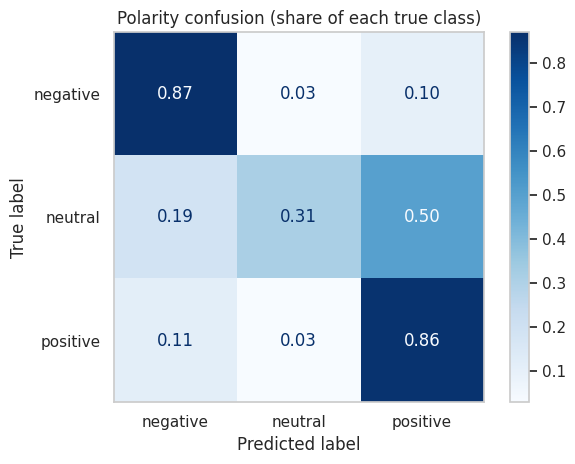

In [22]:
best_polarity_run = polarity_grid.iloc[0]
polarity_steps = PREPROCESSINGS[best_polarity_run.preprocessing]
prepare_polarity_text = build_pipeline(polarity_steps)

polarity_model = make_polarity_model(best_polarity_run.C, CLASS_WEIGHTS[best_polarity_run.class_weight])
polarity_model.fit(with_prepared_text(train_units, prepare_polarity_text), train_units.polarity)

val_polarities = polarity_model.predict(with_prepared_text(val_units, prepare_polarity_text))
polarity_result = polarity_scores(val_units, val_polarities)

clear_units = ~val_units.ambiguous.to_numpy(dtype=bool)
print(f"Best: {best_polarity_run.preprocessing}, C={best_polarity_run.C:g}, class_weight={best_polarity_run.class_weight}")
print(classification_report(val_units.polarity[clear_units], val_polarities[clear_units], zero_division=0))
plot_polarity_confusion(val_units.polarity[clear_units], val_polarities[clear_units])

Accuracy on sentences that mix polarities, compared with the others:

In [23]:
accuracy_by_mixed_sentence(val_units, val_polarities)

,accuracy,aspects
mixed_sentence,,
False,0.891,726
True,0.610,195


In [24]:
for row in polarity_grid.itertuples():
    result_rows.append(result_row("polarity", "tfidf+lr", row.preprocessing, f"C={row.C:g}, class_weight={row.class_weight}",
                                  fit_time_s=row.fit_time_s, macro_f1=row.macro_f1, accuracy=row.accuracy))

**Conclusions (Q6)**

* The best model is `norm+light_stem`, `C=100`, `class_weight="balanced"`, with macro-F1 0.690 and accuracy 0.834.
* Every top run uses `balanced`. Even so, `neutral` stays weak (F1 0.36), with few examples (54 in val).
* Accuracy is 0.894 on sentences with one polarity and 0.610 on mixed ones. This is the expected limit of a linear model, where the aspect only shifts the score. An aspect-aware model should do better here.

## 4. Full pipeline on val

The category model finds the pairs, then the polarity model labels only those pairs. A pair counts as correct when both the category and the polarity are right.

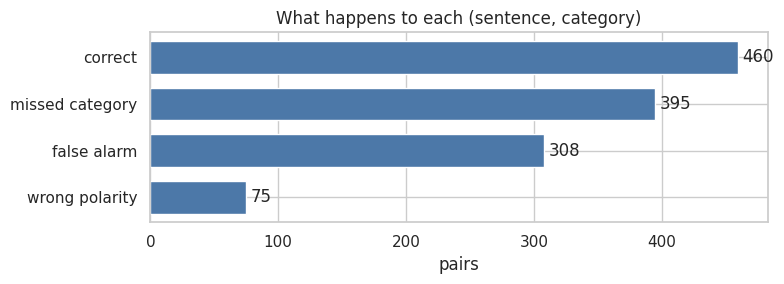

{'category_f1': 0.6034968979131415, 'pipeline_f1': 0.5188945290468133}

In [25]:
predicted_pairs = pairs_from_matrix(val, val_predictions, classes)
predicted_pairs["polarity"] = polarity_model.predict(with_prepared_text(predicted_pairs, prepare_polarity_text))

outcomes = pipeline_outcomes(val_pairs, predicted_pairs)
pipeline_result = pipeline_scores(outcomes)

result_rows.append(result_row("pipeline", "tfidf+lr", threshold_policy=threshold_policy, micro_f1=pipeline_result["pipeline_f1"]))

plot_pipeline_outcomes(outcomes)
pipeline_result

In [26]:
sentence_text = val.set_index("sentence_id").text
error_examples = outcomes[outcomes.status != "correct"].assign(text=lambda table: table.sentence_id.map(sentence_text))
error_examples = error_examples.groupby("status").head(4).sort_values("status")
error_examples[["status", "category", "gold", "predicted", "text"]].reset_index(drop=True)

,status,category,gold,predicted,text
0,false alarm,HOTEL#GENERAL,,positive,من افضل فنادق المدينه المنوره انصح وبشده من ير...
1,false alarm,HOTEL#GENERAL,,positive,مبالََغ في مدحه تصميم وتجديد الفندق يؤكد أنه ...
2,false alarm,SERVICE#GENERAL,,negative,مبالََغ في مدحه تصميم وتجديد الفندق يؤكد أنه ...
3,false alarm,HOTEL#GENERAL,,positive,ترتيب جيد لتوقف عابر استخدمت هذا الفندق كإقامة...
4,missed category,FOOD_DRINKS#QUALITY,positive,,من افضل فنادق المدينه المنوره انصح وبشده من ير...
5,missed category,ROOMS#CLEANLINESS,negative,,رحلة عمل سأظل أتذكر هذا الفندق لسنوات عديدة، ف...
6,missed category,FACILITIES#GENERAL,negative,,(وهم يرشون المكان طوال الوقت ولكن الصراصير لا ...
7,missed category,ROOMS_AMENITIES#COMFORT,negative,,والنوافذ كان بها طبقة واحدة من الزجاج ولذلك كا...
8,wrong polarity,SERVICE#GENERAL,positive,negative,(وهم يرشون المكان طوال الوقت ولكن الصراصير لا ...
9,wrong polarity,SERVICE#GENERAL,neutral,positive,فيه حمام سباحة جميل مع بار صغير ومطعم ذو بوفيه...


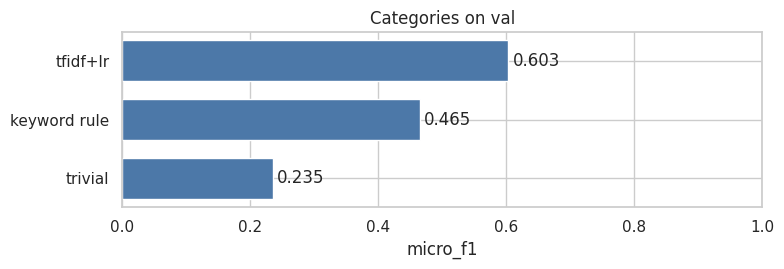

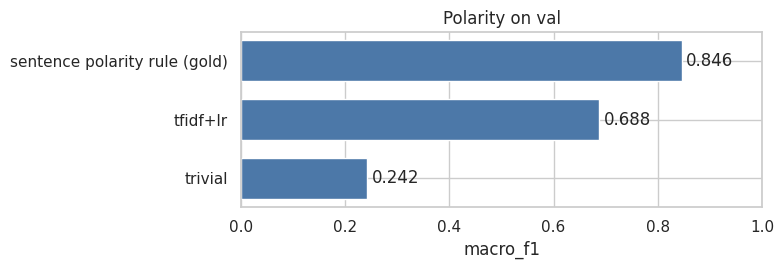

In [27]:
log_results(result_rows)

category_summary = pd.DataFrame({
    "name": ["trivial", "keyword rule", "tfidf+lr"],
    "micro_f1": [trivial_category["micro_f1"], keyword_scores["micro_f1"], category_result["micro_f1"]],
})
plot_model_comparison(category_summary, "micro_f1", title="Categories on val")

polarity_summary = pd.DataFrame({
    "name": ["trivial", "sentence polarity rule (gold)", "tfidf+lr"],
    "macro_f1": [trivial_polarity["macro_f1"], sentence_rule_scores["macro_f1"], polarity_result["macro_f1"]],
})
plot_model_comparison(polarity_summary, "macro_f1", title="Polarity on val")

**Conclusions**

The full pipeline reaches F1 0.520 on val, against 0.160 for the trivial classifier. Category F1 is 0.603, so most of the loss comes from the category step, which sets the limit for any polarity model. These are the numbers the next notebooks have to beat.

## 5. Save the models and val scores

In [28]:
MODELS_DIR.mkdir(exist_ok=True)
thresholds_to_save = np.broadcast_to(chosen_thresholds, len(classes)).tolist()

joblib.dump({
    "model": category_model,
    "steps": category_steps,
    "classes": classes,
    "threshold_policy": threshold_policy,
    "thresholds": thresholds_to_save,
}, MODELS_DIR / "tfidf_lr_category.joblib")

joblib.dump({"model": polarity_model, "steps": polarity_steps}, MODELS_DIR / "tfidf_lr_polarity.joblib")

save_scores(
    "tfidf_lr_category", "val", val_scores,
    {"sentence_id": val.sentence_id.to_numpy()},
    classes,
    meta={"preprocessing": best_run.preprocessing, "C": best_C, "seed": SEED,
          "threshold_policy": threshold_policy, "thresholds": thresholds_to_save},
)

polarity_probabilities = polarity_model.predict_proba(with_prepared_text(val_units, prepare_polarity_text))
save_scores(
    "tfidf_lr_polarity", "val", polarity_probabilities,
    {"sentence_id": val_units.sentence_id.to_numpy(), "category": val_units.category.to_numpy()},
    polarity_model.classes_,
    meta={"preprocessing": best_polarity_run.preprocessing, "C": float(best_polarity_run.C),
          "class_weight": best_polarity_run.class_weight, "seed": SEED},
)

## 6. Test predictions for Part F

Run this section only when the choices above are final. It writes the predictions on the test set for `06_final_test` and prints no score, so nothing here can influence a choice.

In [29]:
test_opinions, test = load_test()
test_units = pair_units(pairs(test_opinions, test))
polarity_columns = [list(polarity_model.classes_).index(polarity) for polarity in POLARITIES]


def polarity_probabilities_of(pair_table):
    return polarity_model.predict_proba(with_prepared_text(pair_table, prepare_polarity_text))[:, polarity_columns]


test_scores = category_model.predict_proba(test.text.map(prepare_category_text))
test_pairs = pairs_from_matrix(test, predict_labels(test_scores, chosen_thresholds), classes)

save_scores("tfidf_lr_polarity", "test", [polarity_probabilities_of(test_units)],
            {"sentence_id": test_units.sentence_id.to_numpy(), "category": test_units.category.to_numpy()}, POLARITIES)
save_scores("tfidf_lr_pipeline", "test", [polarity_probabilities_of(test_pairs)],
            {"sentence_id": test_pairs.sentence_id.to_numpy(), "category": test_pairs.category.to_numpy()}, POLARITIES)
save_scores("tfidf_lr_category", "test", [test_scores], {"sentence_id": test.sentence_id.to_numpy()}, classes, meta={
    "thresholds": thresholds_to_save,
    "train_s": float(best_run.fit_time_s),
    "latency_ms": latency_ms(lambda text: category_model.predict_proba([prepare_category_text(text)]), test.text.head(50).tolist()),
    "size_mb": len(pickle.dumps(category_model)) / 1e6,
})